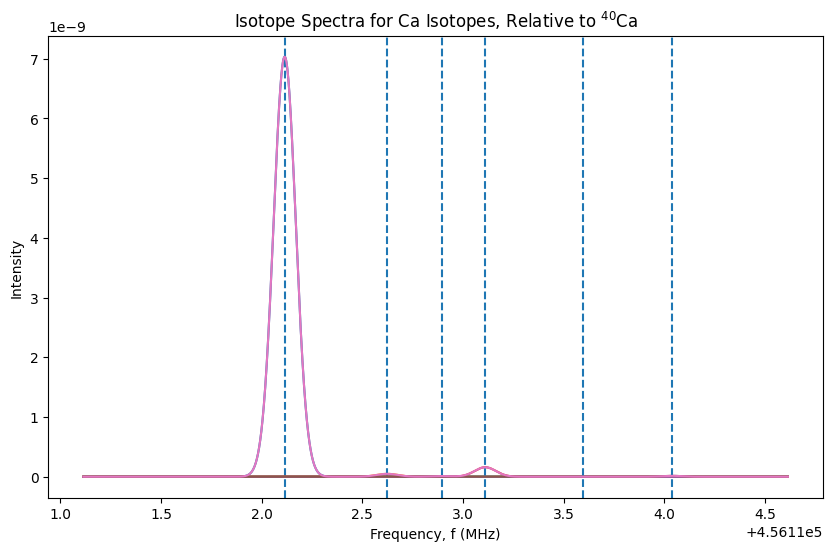

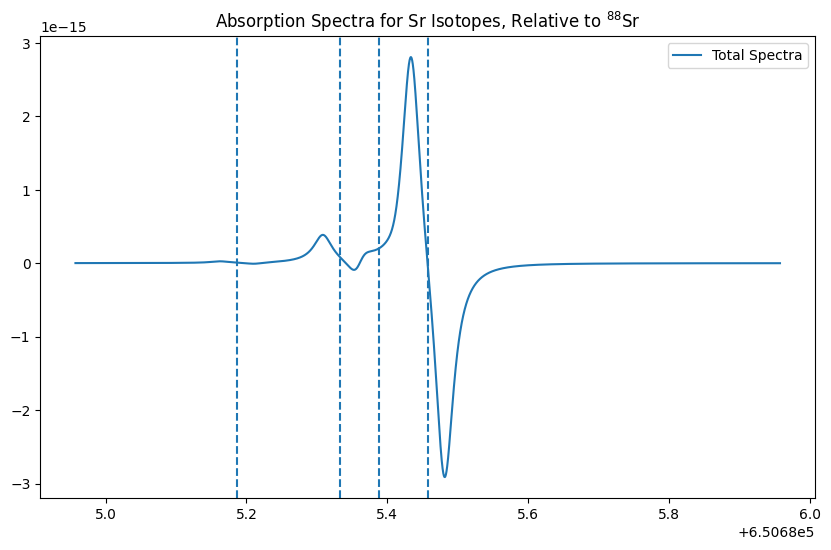

In [3]:
from atom import atom
import numpy as np

Ca = atom("Ca.csv", 657.278e-9, 2.6e3, oven_T = 600 + 273.15, theta = 3 * np.pi / 180)
# print(Ca)
fig, ax = Ca.plot_spectra(Ca.freq - 1e9, Ca.freq + 2.5e9, 1000000, True, True, True, False)
# ax.legend()
# ax.set_yscale("log")

Sr = atom("Sr.csv", 460.7333e-9, 2.01e8)
fig, ax = Sr.plot_absorp_signal(Sr.freq - 0.5e9, Sr.freq + 0.5e9, 100000, True, True, False)
# print(Sr)
ax.legend()

In [11]:
import math
print(1.5*math.log10(40.08) + 2.602)
print(1.5*math.log10(87.62) + 2.602)

5.006391569288784
5.515904873263235


Bad pipe message: %s [b'r\xe4\xc3\x96\xe6\x03\xe3M\x04\xc8\xcf\\\xa1oW\xf2\xd3O\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00', b'B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00\x98\x00\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e\x00\x9f\x00\xa0\x00\xa1\x00\xa2\x00\xa3\x00']
Bad pipe message: %s [b"\xa5\x00\xa6\x00\xa7\x00\xba\x00\xbb\x00\xbc\x00\xbd\x00\xbe\x00\xbf\x00\xc0\x00\xc1\x00\xc2\x00\xc3\x00\xc4\x00\xc5\x13\x01\x13\x02\x13\x03\x13\x04\x13\x05\xc0\x01\xc0\x02\xc0\x03\xc0\x04\xc0\x05\xc0\x06\xc0\x07\xc0\x08\xc0\t\xc0\n\xc0\x0b\xc0\x0c\xc0\r\xc0\x0e\xc0\x0f\xc0\x10\xc0\x11\xc0\x12\xc0\x13\xc0\x14\xc0\x15\xc0\x16\xc0\x17\xc0\x18\xc0\x

In [6]:
from scipy.integrate import quad
import numpy as np
def f(theta, a, L):
    gamma = a / L
    W = (8 * a / 3 / L) / (1 + 8 * a / 3 / L)
    if theta == 0:
        return 1
    if theta > np.arctan(2 * a / L):
        return np.cos(theta) * (1 / (np.pi * np.tan(theta)) * (8 * a / (3 * L)) * ((1 / W) - 1) + (1 / 2))
    else:
        p = L * np.tan(theta) / (2 * a)
        R = np.arccos(p) - p * np.power((1 - p ** 2), (1 / 2))
        return (2 * np.cos(theta) / (np.pi * W)) * ((1 - (W / 2)) * R + (2 / 3) * (1 - W) * (1 - np.power((1 - p ** 2), (3 / 2))) / p) + np.cos(theta) / 2
def fractions(a, L, deg):
    rad = np.radians(deg)
    integrand = lambda th: f(th, a, L) * np.sin(th)
    coll_flux, _ = quad(integrand, 0, rad)
    total_flux, _ = quad(integrand, 0, np.pi / 2)
    return coll_flux / total_flux

a = 2
L = 50.8
div = 3

frac = fractions(a, L, div)
print(f"Fraction of atoms within {div} degrees: {frac:.2%}")

Fraction of atoms within 3 degrees: 2.12%


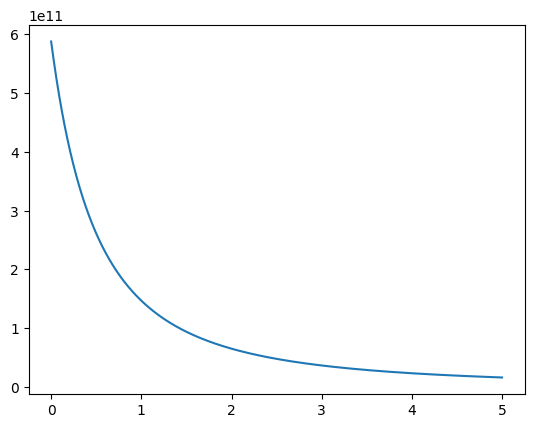

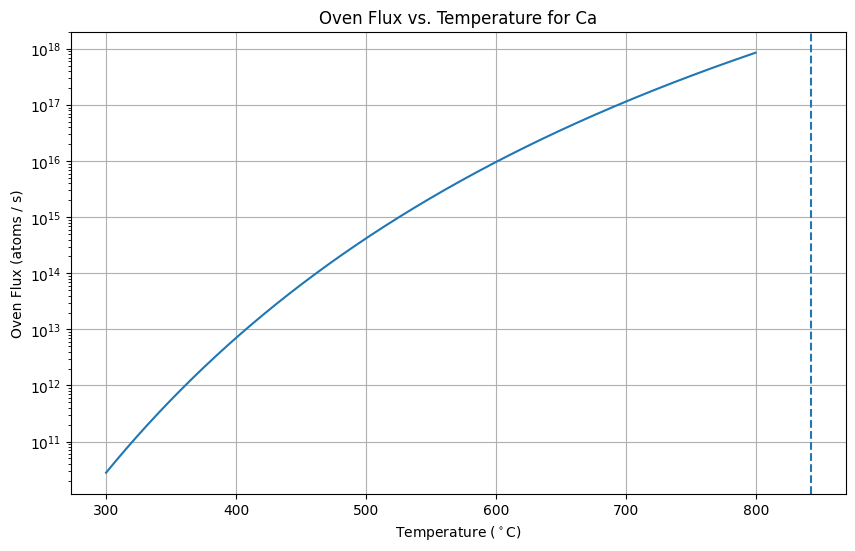

-0.7332831175509826
1.00000010000001


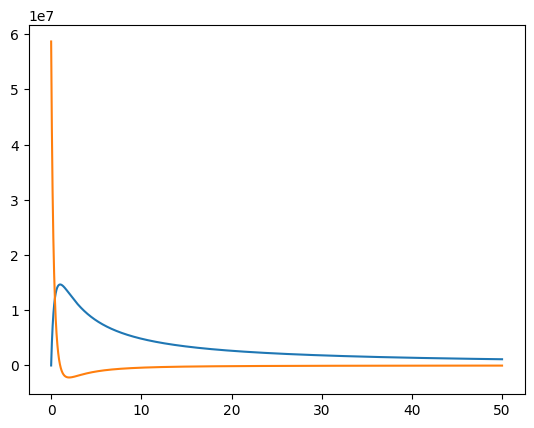

Bad pipe message: %s [b'v\xd9\x85\x192qC0n\x1diVc%\x9a>1\x7f\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00\x98\x00\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e\x00\x9f\x00\xa0\x00\xa1\x00\xa2\x00\xa3\x00\xa4\x00\xa5\x00\xa6\x00\xa7\x00\xba\x00\xbb\x00\xbc\x00\xbd\x00\xbe\x00\xbf\x00\xc0\x00\xc1\x00\xc2\x00\xc3\x00\xc4\x00\xc5\x13\x01\x13\x02\x13\x03\x13\x04\x13', b'\x01\xc0\x02\xc0']
Bad pipe message: %s [b'\x04\xc0']
Bad pipe message: %s [b'\x06\xc0\x07\xc0']
Bad pipe message: %s [b'\t\xc0\n\xc0\x0b\xc0\x0c']
Bad pipe message: %s [b'\xd8\x10\xafa\x11\xe1\x08\xdd\x11\xde\xfe\xd2\xd7\x8b\x91

In [87]:
import matplotlib.pyplot as plt
from scipy.differentiate import derivative as D
from oven import oven
from atom import atom
Ca = atom("Ca.csv")
o = oven(Ca)
def S(g, d, s):
    return 1 + ((2 * d / (g * np.sqrt(1 + s))) ** 2 ) / (1 + s)
def yield_times_selectivity(s, g, d, flux):
    return flux * (s / 2 / (1 + s + (2 * d / g) ** 2)) * S(g, d, s)
plt.plot(np.linspace(0, 5, 1000), S(Ca.A, Ca["44"].shift, np.linspace(0, 5, 1000)))
plt.show()
flux = o.oven_flux(500)
# print(flux * (np.linspace(0, 5, 1000) / (1 + np.linspace(0, 5, 1000) + (2 * Ca["44"].shift / Ca.A) ** 2))
fig, ax = o.plot_oven_flux(300, 800, True)
s = np.linspace(0, 50, 10000000)
plt.show()
plt.plot(s, yield_times_selectivity(s, Ca.A, Ca["44"].shift, o.oven_flux(500)))
plt.plot(s, D(yield_times_selectivity, s, args = (Ca.A, Ca["44"].shift, o.oven_flux(500))).df)
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx
print(D(yield_times_selectivity, s, args = (Ca.A, Ca["44"].shift, o.oven_flux(500))).df[find_idx(D(yield_times_selectivity, s, args = (Ca.A, Ca["44"].shift, o.oven_flux(500))).df, find_nearest(D(yield_times_selectivity, s, args = (Ca.A, Ca["44"].shift, o.oven_flux(500))).df, 0))])
print(s[find_idx(D(yield_times_selectivity, s, args = (Ca.A, Ca["44"].shift, o.oven_flux(500))).df, find_nearest(D(yield_times_selectivity, s, args = (Ca.A, Ca["44"].shift, o.oven_flux(500))).df, 0))])
plt.show()